In [10]:
import pandas as pd

df = pd.read_csv("data/raw/reviews.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(205052, 6)
['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [8]:
import os
path = "data/raw/Dataset-SA 2.csv"
print(os.path.exists(path))

False


In [9]:
import os
path = "data/raw/reviews.csv"
print(os.path.exists(path))

True


In [11]:
print(df.shape)
print(df.isnull().sum())
print("duplicates:", df.duplicated().sum())

(205052, 6)
product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64
duplicates: 34375


In [12]:
print("unique products:", df["product_name"].nunique())
df["product_name"].value_counts().head(15)

unique products: 958


product_name
cello Pack of 18 Opalware Cello Dazzle Lush Fiesta Opalware Dinner Set, 18 Pieces Dinner SetÃÂ ÃÂ (White, Microwave Safe)                   6005
Lakm?? Eyeconic Kajal Twin Pack??????????(Deep Black, 0.7 g)                                                                                  5000
Mi 5A 80 cm (32 inch) HD Ready LED Smart Android TV with Dolby Audio (2022 Model)                                                             2205
cello Pack of 18 Opalware Cello Dazzle Lush Fiesta Opalware Dinner Set 18 Pieces Dinner SetWhite Microwave Safe                               2095
Home Sizzler 153 cm 502 ft Polyester Room Darkening Window Curtain Pack Of 2Floral Brown                                                      2012
Mi 3i 10000 mAh Power Bank (Fast Charging, 18W)ÐÒ?ÐÓ®ÐÂ ÐÒ?ÐÓ®ÐÂ (Blue, Lithium Polymer)                                              2006
Singer FM 1409 Electric Sewing MachineÐÒ?ÐÓ®ÐÂ ÐÒ?ÐÓ®ÐÂ ( Built-in Stitches 9)                   

/Users/rajnishraj/projects/reviewlens/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 131 (\x83) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


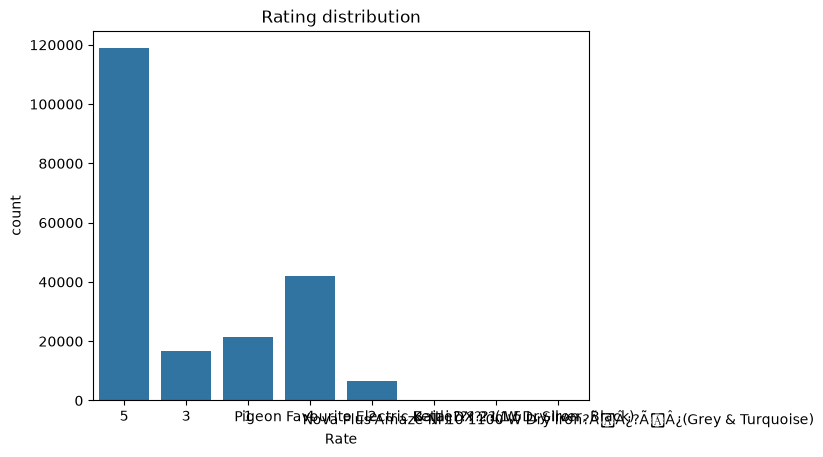

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="Rate", data=df)
plt.title("Rating distribution")
plt.show()

In [15]:
df["Rate"] = pd.to_numeric(df["Rate"], errors="coerce")
df = df.dropna(subset=["Rate", "Summary"])

def rating_to_sentiment(r):
    if r >= 4:
        return "positive"
    elif r == 3:
        return "neutral"
    else:
        return "negative"

df["label"] = df["Rate"].apply(rating_to_sentiment)
print(df["label"].value_counts())

label
positive    160649
negative     27790
neutral      16599
Name: count, dtype: int64


In [16]:
pd.crosstab(df["Sentiment"], df["label"])

label,negative,neutral,positive
Sentiment,,,
negative,23500,3023,1708
neutral,2282,3660,4292
positive,2008,9916,154649


In [17]:
df["word_count"] = df["Summary"].astype(str).str.split().str.len()
print(df["word_count"].describe())
df.sample(8, random_state=42)[["Summary", "Rate", "label"]]

count    205038.000000
mean          7.758845
std          13.076305
min           1.000000
25%           2.000000
50%           3.000000
75%           8.000000
max         108.000000
Name: word_count, dtype: float64


,Summary,Rate,label
4613,the review here seems fake as soundbar is norm...,1.0,negative
142353,super quality,5.0,positive
40357,good product,5.0,positive
29279,good product,4.0,positive
204461,good product,4.0,positive
30560,nyc,5.0,positive
141922,nice item,5.0,positive
186575,amazing,5.0,positive


In [18]:
before = len(df)
df = df.drop_duplicates()
df = df.dropna(subset=["Summary"])
print("rows before:", before, "-> after:", len(df))

# How many identical Summary texts remain (e.g. "good", "nice")?
print("repeated Summary texts:", df["Summary"].duplicated().sum())
df["Summary"].value_counts().head(10)

rows before: 205038 -> after: 170664
repeated Summary texts: 77744


Summary
good                 7088
nice                 4781
good product         4052
nice product         3217
super                2170
very good            1881
very nice            1773
very good product    1397
ok                   1392
good quality         1242
Name: count, dtype: int64

In [19]:
import re

keywords = [
    r"\btv\b", r"\bled\b", r"smart tv", r"television", r"\bmobile\b", r"\bgb ram\b", r"\bram\b",
    r"power bank", r"\bmah\b", r"charger", r"\bcable\b", r"earphone", r"headphone", r"earbud",
    r"neckband", r"bluetooth", r"speaker", r"soundbar", r"smartwatch", r"smart watch",
    r"laptop", r"\bmouse\b", r"keyboard", r"router", r"memory card", r"microsdxc", r"pen drive",
    r"hard disk", r"\bssd\b", r"webcam", r"camera", r"printer", r"monitor", r"tablet",
    r"trimmer", r"shaver", r"epilator", r"hair dryer", r"straightener", r"kettle",
    r"\bcooler\b", r"\bfan\b", r"heater", r"geyser", r"\biron\b", r"mixer", r"grinder",
    r"induction", r"microwave", r"\boven\b", r"refrigerator", r"washing machine",
    r"air conditioner", r"\bac\b", r"sewing machine", r"air purifier", r"vacuum cleaner",
    r"water purifier", r"extension board", r"\bled bulb\b", r"\bwatt\b",
]
pattern = "|".join(keywords)

df["is_electronics"] = df["product_name"].str.contains(pattern, case=False, regex=True)

print(df["is_electronics"].value_counts())
print("unique electronics products:", df.loc[df["is_electronics"], "product_name"].nunique())

is_electronics
False    95584
True     75080
Name: count, dtype: int64
unique electronics products: 298


In [20]:
pd.set_option("display.max_colwidth", 80)
(df.loc[df["is_electronics"], "product_name"]
   .drop_duplicates()
   .sample(40, random_state=1)
   .to_frame())

,product_name
109219,TP-Link Archer C6 MU-MIMO Gigabit 1200 Mbps Wireless Router?ÐÒÐÒ?ÐÒÐÒ...
168619,Hiru Party Light 50W RGB LED Brick Light Remote IP65 LED Flood Light Flood ...
24435,"Google Nest Hub (2nd gen), Display with Google Assistant Smart Speaker??????..."
125519,ANTIOUE MART Wooden Set Top Box Stand Wall Mounted TV Cabinets Wall Selves H...
170607,BAJAJ Waterproof 1500 W Shock Proof Immersion Heater Rodwater
176117,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1 Jar Multicolor
185682,Flipkart Perfect Homes Sirena Engineered Wood TV Entertainment UnitFinish Co...
33728,songbird 4 INCH 280 W MAX DOOR SPEAKER With Dual SB-B10-15S Coaxial Car Spea...
14038,"D&V ENGINEERING Sturdy Set top Box Stand,DVD,DTH,Telephone, WiFi Modems Stan..."
93332,"Flipkart SmartBuy SLICK Multi Angle Mobile Stand. Phone Holder. Portable,Fol..."


In [21]:
(df.loc[~df["is_electronics"], "product_name"]
   .drop_duplicates()
   .sample(40, random_state=1)
   .to_frame())

,product_name
169423,US DZIRE 512 Ganeshji craft Ceiling light wooden lamp shade With Bulb Hangi...
137995,Auto Hub Microfiber Vehicle Washing ClothPack Of 3 800 GSM
163344,Saral Home Brown Polyester Runner45 cm X 120 cm Rectangle
43833,Cotton Blend Embellished Maroon Men Dupatta
58244,MALABAR GOLD & DIAMONDS NBJCHN024 Rope Chain Yellow Gold Precious Chain?????...
124747,Mi Box 4k Media Streaming Device????(Black)
195266,Ebee Engineered Wood Computer DeskModular Finish Color Wenge DIYDoItYourself
49334,"Men Solid Single Breasted Wedding, Casual, Festive Blazer??????(Blue)"
36707,Bestie Toys Adjustable kids Suitable Quad Roller Skates - Size 6 years to 12...
39650,WDIZE Magic Book For Kids ( 4 Book + 10 Refill + 1 Pen + 1 Grip )


In [22]:
import os
os.makedirs("data/processed", exist_ok=True)

df.to_csv("data/processed/reviews_all_clean.csv", index=False)
df[df["is_electronics"]].to_csv("data/processed/reviews_electronics.csv", index=False)

In [23]:
top_texts = df["Summary"].value_counts().head(10).index
pd.crosstab(df[df["Summary"].isin(top_texts)]["Summary"],
            df[df["Summary"].isin(top_texts)]["Rate"])

Rate,1.0,2.0,3.0,4.0,5.0
Summary,,,,,
good,52,23,976,2218,3819
good product,23,10,318,1234,2467
good quality,1,1,83,376,781
nice,25,11,527,1378,2840
nice product,15,7,207,943,2045
ok,31,33,399,405,524
super,8,6,103,443,1610
very good,10,6,79,417,1369
very good product,2,3,45,268,1079


In [24]:
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

label
positive    130203
negative     26072
neutral      14389
Name: count, dtype: int64
label
positive    0.763
negative    0.153
neutral     0.084
Name: proportion, dtype: float64


In [25]:
names = df.loc[df["is_electronics"], "product_name"].drop_duplicates()
hits = {kw: names.str.contains(kw, case=False, regex=True).sum() for kw in keywords}
print(pd.Series(hits).sort_values(ascending=False).head(20))

# Look at examples for the risky keywords
for kw in [r"\bmobile\b", r"\bram\b", r"\bac\b", r"\bled\b", r"camera", r"\bfan\b", r"tablet"]:
    print("\n==", kw)
    print(names[names.str.contains(kw, case=False, regex=True)].head(8).to_string())

\btv\b          38
grinder         36
bluetooth       33
\bmobile\b      26
\bled\b         26
laptop          23
heater          18
speaker         16
charger         14
\bssd\b         14
mixer           13
\biron\b        13
\bcable\b       13
air purifier    12
router          11
camera          10
\bfan\b          9
microwave        9
soundbar         8
tablet           7
dtype: int64

== \bmobile\b
14498    SQUARO ONLINE STORE Unbreakable Setup Box stand/WiFi Router/DTH Telephone/Mo...
14524    SQUARO ONLINE STORE Unbreakable Setup Box stand/WiFi Router/DTH Telephone/Mo...
32851    gyzmofreakz 3.5mm Clip Microphone For Youtube | Collar Mike for Voice Record...
33880    Shopfloor.XYZ 3.5mm Clip Microphone For Youtube, Collar Mike For Voice Recor...
34080    mobspy 3.5mm Clip Microphone For Youtube | Collar Mic for Voice Recording | ...
69619    Urban Terrain Rio with Complete Accessories & Mobile Tracking App 26 T Hybri...
69932    Urban Terrain Berlin with Complete Accessories & 

In [26]:
add_keywords = [r"dishwasher", r"streaming device", r"projector", r"\bhdmi\b",
                r"cctv", r"stabilizer", r"home theatre", r"chromecast"]
include = "|".join(keywords + add_keywords)

exclude = (r"\bstand\b|\bcabinets?\b|entertainment unit|dinner set|opalware|"
           r"holder|sleeve|\bcover\b|\bcase\b|\bpouch\b|\bbag\b")

name = df["product_name"]
df["is_electronics"] = (name.str.contains(include, case=False, regex=True)
                        & ~name.str.contains(exclude, case=False, regex=True))

print(df["is_electronics"].value_counts())
print("unique electronics products:", df.loc[df["is_electronics"], "product_name"].nunique())

is_electronics
False    103260
True      67404
Name: count, dtype: int64
unique electronics products: 284


In [27]:
(df.loc[df["is_electronics"], "product_name"]
   .drop_duplicates()
   .sample(40, random_state=2)
   .to_frame())

,product_name
3491,"OnePlus Bullets Wireless Z2 Bluetooth Headset??????(Acoustic Red, In the Ear)"
167229,Hillgrove 10in1 Biggers 25W Soldering Iron Kit 25 W SimpleFlat Pointed Tip
176243,Briqre Victory Nutri Blend 20000 RPM Mixer Grinder 500 Juicer Mixer Grinder ...
136911,ROYAL RJ Round Electric USB Mini Humidifier Aroma Oil Diffuser Air Humidifie...
188145,SAMSUNG EVO Plus 64 GB MicroSDXC Class 10 95 MBs Memory CardWith Adapter
83849,APPLE 2020 Macbook Air M1 - (8 GB/256 GB SSD/Mac OS Big Sur) MGN93HN/AÐÒ?Ð...
13248,SAMSUNG DW60M5042FW/TL Free Standing 13 Place Settings Dishwasher
138478,Crust v50 Car Bluetooth Device with FM Transmitter Audio Receiver Car Charge...
816,"Crompton 75 L Desert Air Cooler??????(White, Teal, ACGC-DAC751)"
89354,"SB 30 W 4 A Mobile 30W -VOOC,DART,FLASH with Type-C Cable Charging Adapter T..."


In [28]:
elec = df[df["is_electronics"]].copy()
print(len(elec))
print(elec["label"].value_counts())
print(elec["label"].value_counts(normalize=True).round(3))

67404
label
positive    52435
negative     9931
neutral      5038
Name: count, dtype: int64
label
positive    0.778
negative    0.147
neutral     0.075
Name: proportion, dtype: float64


In [1]:
elec.to_csv("data/processed/reviews_electronics.csv", index=False)
df.to_csv("data/processed/reviews_all_clean.csv", index=False)

NameError: name 'elec' is not defined

In [5]:
import os, sys
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root); sys.path.insert(0, root)

import pandas as pd
from src.preprocess import clean_text

tests = ["Not good, battery doesn't last!!!",
         "SUPERRRR product 👍 READ MORE",
         "Very bad. Can't recommend, waste of money"]
for t in tests:
    print(repr(t), "->", repr(clean_text(t)))

"Not good, battery doesn't last!!!" -> 'not good battery not last'
'SUPERRRR product 👍 READ MORE' -> 'superr product'
"Very bad. Can't recommend, waste of money" -> 'very bad not recommend waste money'


In [6]:
assert "not" in clean_text("not good")

In [7]:
elec = pd.read_csv("data/processed/reviews_electronics.csv")
elec["clean_text"] = elec["Summary"].astype(str).apply(clean_text)

# Some reviews may become empty after cleaning (e.g. only emojis)
print("empty after cleaning:", (elec["clean_text"].str.strip() == "").sum())
elec = elec[elec["clean_text"].str.strip() != ""]

print(len(elec))
elec[["Summary", "clean_text", "label"]].sample(8, random_state=3)

empty after cleaning: 3
67401


,Summary,clean_text,label
24970,very good product,very good product,positive
11630,just go for it,go,positive
67129,dont buy because camera quality very bad,dont buy camera quality very bad,negative
46783,awesome one wonderful no words for praise100 f...,awesome one wonderful no word praise markssoun...,positive
22203,portable machine in the true sense worth every...,portable machine true sense worth every penny,positive
39025,value of money,value money,positive
35569,very good router,very good router,positive
55561,super,super,positive


In [8]:
elec.to_csv("data/processed/reviews_electronics_clean.csv", index=False)

In [4]:
elec = pd.read_csv("data/processed/reviews_electronics.csv")
elec["clean_text"] = elec["Summary"].astype(str).apply(clean_text)
elec = elec[elec["clean_text"].str.strip() != ""]
print(len(elec))
print(clean_text("dont buy this, cant recommend"))   # expect: not buy not recommend
elec.to_csv("data/processed/reviews_electronics_clean.csv", index=False)

67401
not buy not recommend


In [3]:
import os, sys
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root); sys.path.insert(0, root)

import pandas as pd
from src.preprocess import clean_text